# 16 — Inferência Bayesiana

No notebook 06, o Teorema de Bayes atualizou a probabilidade de um **evento** (estar doente) com uma evidência (o exame). Agora vamos usar a mesma regra para algo mais ambicioso: atualizar a nossa crença sobre um **parâmetro desconhecido**, como a taxa de acerto de um jogador ou a proporção de fumantes de um restaurante.

Na estatística que vimos até aqui (a **frequentista**), o parâmetro é um número fixo e desconhecido, e a incerteza está nos **dados** (ICs, p-valores). Na **inferência bayesiana**, a incerteza sobre o parâmetro é descrita por uma **distribuição de probabilidade**:

$$\underbrace{P(\theta \mid \text{dados})}_{\text{posteriori}} \propto \underbrace{P(\text{dados} \mid \theta)}_{\text{verossimilhança (notebook 13)}} \times \underbrace{P(\theta)}_{\text{priori}}$$

Neste notebook vamos:
- Usar a distribuição **Beta** como priori para uma proporção
- Atualizar a priori com dados: o modelo **Beta-Binomial**, por fórmula e por **aproximação em grade**
- Interpretar a posteriori como um **encolhimento** entre a priori e os dados
- Construir **intervalos de credibilidade** e compará-los com os de confiança
- Fazer um **teste A/B bayesiano**
- Descobrir que **Ridge e Lasso são estimativas bayesianas** (MAP) com prioris normal e Laplace

## 1. Importando bibliotecas e carregando os dados

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.optimize import minimize
from sklearn.linear_model import Ridge, LinearRegression

pd.set_option("display.precision", 4)
plt.rcParams["figure.dpi"] = 100
rng = np.random.default_rng(42)

gorjetas = sns.load_dataset("tips")

## 🎓 Conceito: a distribuição Beta como priori para uma proporção

Para um parâmetro que é uma **proporção** ($p$ entre 0 e 1), a priori mais usada é a distribuição **Beta**($a$, $b$). Uma forma intuitiva de ler os parâmetros: é como se, **antes** de ver os dados, já tivéssemos observado **$a$ sucessos e $b$ fracassos** "imaginários".
- **Beta(1, 1)** é a **uniforme**: nenhuma preferência, todo $p$ é igualmente plausível.
- **Beta(7, 3)**: acreditamos que $p$ está perto de 0,7, com a confiança de "10 observações".
- **Beta(70, 30)**: a mesma crença central (0,7), mas com muito mais confiança.
- A média da Beta é $\frac{a}{a + b}$.

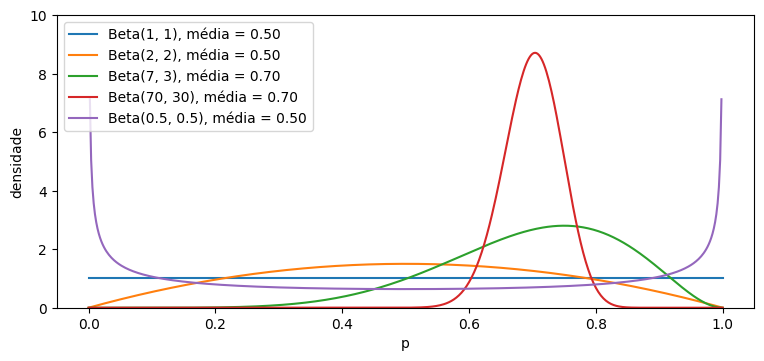

In [2]:
p = np.linspace(0, 1, 501)
fig, ax = plt.subplots(figsize=(9, 3.8))
for a, b in [(1, 1), (2, 2), (7, 3), (70, 30), (0.5, 0.5)]:
    ax.plot(p, stats.beta.pdf(p, a, b), label=f"Beta({a}, {b}), média = {a / (a + b):.2f}")
ax.set_ylim(0, 10)
ax.set_xlabel("p")
ax.set_ylabel("densidade")
ax.legend()
plt.show()

## 🎓 Conceito: o modelo Beta-Binomial

Se a priori é Beta($a$, $b$) e observamos $k$ sucessos em $n$ tentativas (verossimilhança binomial), a posteriori é **outra Beta**:

$$p \mid \text{dados} \sim \text{Beta}(a + k,\; b + n - k)$$

É só **somar** os sucessos e fracassos reais aos imaginários. Quando a posteriori é da mesma família da priori, dizemos que a priori é **conjugada**. Isso deixa as contas triviais.

Exemplo: um jogador novo do time faz **10 lances livres e acerta 9**. Qual a taxa de acerto dele? A proporção observada (o EMV do notebook 13) é 90%. Mas sabemos que, na liga, a maioria dos jogadores acerta entre 60% e 85%. Vamos codificar isso numa priori **Beta(15, 5)** (média de 75%).

Antes de usar a fórmula, vamos fazer a conta de Bayes "na força bruta", com uma **grade** de valores de $p$: multiplicar priori × verossimilhança em cada ponto e normalizar. Esse método funciona para **qualquer** priori e verossimilhança (com poucos parâmetros).

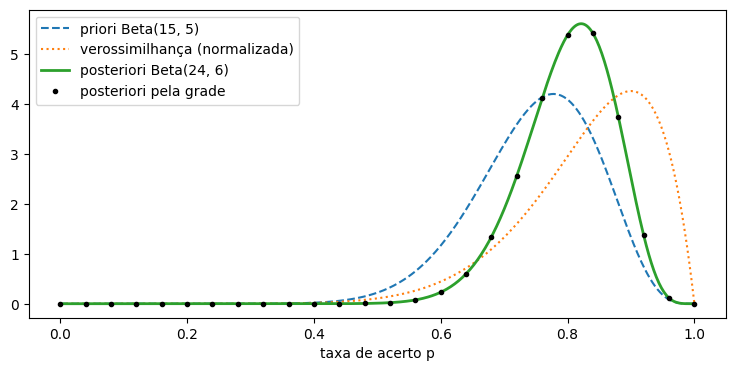

Proporção observada (EMV):  0.900
Média da priori:            0.750
Média da posteriori:        0.800
Grade e fórmula coincidem?  True


In [3]:
a0, b0 = 15, 5      # priori
k, n = 9, 10        # dados: 9 acertos em 10

# Aproximação em grade: priori × verossimilhança, normalizada para a área dar 1.
priori = stats.beta.pdf(p, a0, b0)
verossimilhanca = stats.binom.pmf(k, n, p)
nao_normalizada = priori * verossimilhanca
posteriori_grade = nao_normalizada / np.trapezoid(nao_normalizada, p)

# Pela fórmula conjugada.
posteriori = stats.beta(a0 + k, b0 + n - k)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(p, priori, label=f"priori Beta({a0}, {b0})", linestyle="--")
ax.plot(p, verossimilhanca / np.trapezoid(verossimilhanca, p), label="verossimilhança (normalizada)", linestyle=":")
ax.plot(p, posteriori.pdf(p), label=f"posteriori Beta({a0 + k}, {b0 + n - k})", linewidth=2)
ax.plot(p[::20], posteriori_grade[::20], "ko", markersize=3, label="posteriori pela grade")   # [::20] = um ponto a cada 20
ax.set_xlabel("taxa de acerto p")
ax.legend()
plt.show()

print(f"Proporção observada (EMV):  {k / n:.3f}")
print(f"Média da priori:            {a0 / (a0 + b0):.3f}")
print(f"Média da posteriori:        {posteriori.mean():.3f}")
print(f"Grade e fórmula coincidem?  {np.allclose(posteriori_grade, posteriori.pdf(p), atol=1e-3)}")

**Conclusão:** a posteriori (verde) fica **entre** a priori (azul, centrada em 0,75) e a verossimilhança (laranja, com pico em 0,90), e é mais **estreita** que as duas: juntar duas fontes de informação reduz a incerteza. A média da posteriori é **0,80**: os 9 acertos em 10 puxaram a nossa crença para cima, mas não até 0,90, porque 10 arremessos são pouca evidência diante do que sabemos sobre a liga.

Os pontos pretos, calculados pela grade (priori × verossimilhança, normalizada), caem exatamente sobre a curva da fórmula Beta(24, 6). A fórmula conjugada é só um atalho para a mesma conta.

## 🎓 Conceito: a posteriori como encolhimento

A média da posteriori Beta-Binomial pode ser reescrita como uma **média ponderada** entre a média da priori e a proporção observada:

$$E[p \mid \text{dados}] = \frac{a + k}{a + b + n} = \underbrace{\frac{a + b}{a + b + n}}_{\text{peso da priori}} \cdot \frac{a}{a + b} + \underbrace{\frac{n}{a + b + n}}_{\text{peso dos dados}} \cdot \frac{k}{n}$$

- Com **poucos dados** ($n$ pequeno), a priori pesa mais e a estimativa é **encolhida** em direção a ela.
- Com **muitos dados**, o peso dos dados vai a 1, e a posteriori converge para o EMV: os dados "vencem" qualquer priori razoável.

É exatamente o estimador encolhido do notebook 11, que trocava um pouco de viés por muito menos variância. A priori diz **para onde** encolher e **quanto**.

In [4]:
# Simulamos um jogador cuja taxa VERDADEIRA é 0,78 (que não conhecemos) e acompanhamos as duas estimativas
# ao longo da temporada, sempre com a mesma priori Beta(15, 5).
taxa_real = 0.78
arremessos = rng.random(500) < taxa_real
linhas = []
for n_i in [10, 30, 100, 500]:
    k_i = arremessos[:n_i].sum()
    post = stats.beta(a0 + k_i, b0 + n_i - k_i)
    linhas.append({"arremessos": n_i, "acertos": k_i, "EMV (k/n)": k_i / n_i,
                   "média da posteriori": post.mean(), "peso da priori": (a0 + b0) / (a0 + b0 + n_i)})
pd.DataFrame(linhas).set_index("arremessos")

,acertos,EMV (k/n),média da posteriori,peso da priori
arremessos,,,,
10,7,0.7000,0.7333,0.6667
30,22,0.7333,0.7400,0.4000
100,82,0.8200,0.8083,0.1667
500,393,0.7860,0.7846,0.0385


**Conclusão:** com **10 arremessos**, a priori ainda tem peso de **67%**, e a posteriori (0,733) fica entre a priori (0,75) e o EMV (0,70). Com **100**, o peso da priori cai para 17%, e com **500**, para **3,8%**: a posteriori (0,785) praticamente coincide com o EMV (0,786), e as duas estão perto da taxa verdadeira de 0,78.

A priori importa muito no começo e quase nada no fim. Repare no caso de 100 arremessos: o jogador teve uma boa fase (82%), e a posteriori (**0,808**) "desconfiou" um pouco desse número, puxando-o na direção da média da liga. Com amostras pequenas, esse ceticismo costuma acertar mais; é a troca entre viés e variância do notebook 11.

## 🎓 Conceito: intervalo de credibilidade

Com a posteriori em mãos, um **intervalo de credibilidade** de 95% é uma faixa que contém 95% da probabilidade da posteriori. Diferente do intervalo de confiança (notebook 11), ele tem a interpretação que todo mundo **gostaria** que o IC tivesse:

- **IC frequentista de 95%:** "este **método** acerta em 95% das amostras". Sobre este intervalo específico, nada se diz.
- **Intervalo de credibilidade de 95%:** "dadas a priori e os dados, há **95% de probabilidade** de o parâmetro estar neste intervalo".

O preço é ter de escolher uma priori. Com prioris **fracas** (como a uniforme) e dados razoáveis, os dois intervalos costumam ficar muito parecidos.

In [5]:
from statsmodels.stats.proportion import proportion_confint

for rotulo, (a, b) in {"priori uniforme Beta(1, 1)": (1, 1), "priori informativa Beta(15, 5)": (a0, b0)}.items():
    post = stats.beta(a + k, b + n - k)
    print(f"{rotulo:>32}: intervalo de credibilidade 95% = [{post.ppf(0.025):.3f}, {post.ppf(0.975):.3f}]")
wilson = proportion_confint(k, n, method="wilson")
print(f"{'IC frequentista (Wilson)':>32}: [{wilson[0]:.3f}, {wilson[1]:.3f}]")

# Perguntas diretas sobre o parâmetro, que só a abordagem bayesiana responde:
post = stats.beta(a0 + k, b0 + n - k)
print(f"\nP(taxa de acerto > 80% | dados) = {post.sf(0.8):.3f}")

      priori uniforme Beta(1, 1): intervalo de credibilidade 95% = [0.587, 0.977]
  priori informativa Beta(15, 5): intervalo de credibilidade 95% = [0.642, 0.920]
        IC frequentista (Wilson): [0.596, 0.982]

P(taxa de acerto > 80% | dados) = 0.537


**Conclusão:** com a priori **uniforme**, o intervalo de credibilidade **[0,587; 0,977]** fica muito parecido com o IC frequentista de Wilson **[0,596; 0,982]**: com uma priori que não acrescenta informação, as duas abordagens concordam na prática. Com a priori **informativa**, o intervalo fica mais estreito (**[0,642; 0,920]**), porque a priori acrescenta o equivalente a 20 arremessos de informação.

E a abordagem bayesiana responde diretamente à pergunta que importa para o técnico: há **53,7%** de probabilidade de a taxa de acerto desse jogador passar de 80%. Uma afirmação desse tipo é impossível na estatística frequentista, em que o parâmetro não tem probabilidade.

## 2. Encolhimento na prática: a proporção de fumantes por dia

No notebook 11, a proporção de fumantes da sexta-feira (78,9%) vinha de apenas 19 mesas. Uma abordagem bayesiana comum é usar os **dados de todos os grupos** para construir a priori (o chamado **Bayes empírico**): a priori é centrada na proporção geral, com uma força escolhida, e cada dia é atualizado com os seus próprios dados. Grupos pequenos são mais encolhidos.

In [6]:
geral = (gorjetas["smoker"] == "Yes").mean()
forca = 20   # a priori "vale" 20 mesas imaginárias
a_dia, b_dia = forca * geral, forca * (1 - geral)

linhas = []
for dia, grupo in gorjetas.groupby("day", observed=True):
    k_d = (grupo["smoker"] == "Yes").sum()
    n_d = len(grupo)
    post = stats.beta(a_dia + k_d, b_dia + n_d - k_d)
    linhas.append({"dia": dia, "mesas": n_d, "proporção observada": k_d / n_d, "posteriori (média)": post.mean(),
                   "cred. 2,5%": post.ppf(0.025), "cred. 97,5%": post.ppf(0.975)})
print(f"Priori: Beta({a_dia:.2f}, {b_dia:.2f}), centrada na proporção geral de {geral:.3f}\n")
pd.DataFrame(linhas).set_index("dia")

Priori: Beta(7.62, 12.38), centrada na proporção geral de 0.381



,mesas,proporção observada,posteriori (média),"cred. 2,5%","cred. 97,5%"
dia,,,,,
Thur,62,0.2742,0.3003,0.2066,0.4032
Fri,19,0.7895,0.5801,0.4241,0.7282
Sat,87,0.4828,0.4638,0.3705,0.5583
Sun,76,0.2500,0.2773,0.1929,0.3705


**Conclusão:** todos os dias foram encolhidos em direção à proporção geral (38,1%), mas **na proporção da sua incerteza**:
- A **sexta**, com só **19 mesas**, foi a mais encolhida: de 78,9% para **58,0%**. Ainda é o dia com mais fumantes, mas a estimativa ficou mais cautelosa.
- O **sábado**, com 87 mesas, quase não se mexeu (48,3% → 46,4%).
- Quinta e domingo, abaixo da média geral, foram puxados para cima (27,4% → 30,0% e 25,0% → 27,7%).

Esse é o raciocínio por trás de rankings justos com poucos dados (um produto com uma única avaliação de 5 estrelas **não** deveria ficar no topo). A força da priori (20 mesas) foi escolhida por nós; no Bayes empírico completo, ela também seria estimada a partir dos dados.

## 3. Um teste A/B bayesiano

Duas versões de um site: a **A** teve 120 compras em 1.000 visitas (12,0%) e a **B**, 145 em 1.000 (14,5%). Na abordagem bayesiana, cada taxa de conversão tem a sua posteriori, e podemos responder diretamente: **qual a probabilidade de B ser melhor que A?** E **de quanto**?

A conta é feita por **simulação**: sorteamos muitos valores de cada posteriori e comparamos.

P(B > A | dados)          = 0.950
Ganho esperado (B - A)    = 0.0249   intervalo de credibilidade 95%: [-0.0046, 0.0546]
P(ganho > 1 ponto)        = 0.837

Frequentista (qui-quadrado): p-valor = 0.113


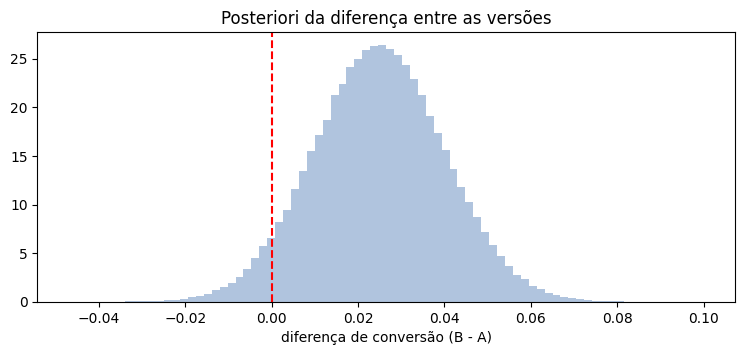

In [7]:
post_a = stats.beta(1 + 120, 1 + 1_000 - 120)   # priori uniforme
post_b = stats.beta(1 + 145, 1 + 1_000 - 145)
amostras_a = post_a.rvs(200_000, random_state=rng)
amostras_b = post_b.rvs(200_000, random_state=rng)
diferenca = amostras_b - amostras_a

print(f"P(B > A | dados)          = {np.mean(diferenca > 0):.3f}")
print(f"Ganho esperado (B - A)    = {diferenca.mean():.4f}   intervalo de credibilidade 95%: [{np.percentile(diferenca, 2.5):.4f}, {np.percentile(diferenca, 97.5):.4f}]")
print(f"P(ganho > 1 ponto)        = {np.mean(diferenca > 0.01):.3f}")

# A versão frequentista: o teste qui-quadrado do notebook 12 para a tabela 2×2.
tabela = np.array([[120, 880], [145, 855]])
print(f"\nFrequentista (qui-quadrado): p-valor = {stats.chi2_contingency(tabela)[1]:.3f}")

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(diferenca, bins=80, density=True, color="lightsteelblue")
ax.axvline(0, color="red", linestyle="--")
ax.set_xlabel("diferença de conversão (B - A)")
ax.set_title("Posteriori da diferença entre as versões")
plt.show()

**Conclusão:** a posteriori diz que há **95,0%** de probabilidade de B converter mais que A, com um ganho esperado de **2,5 pontos percentuais** e um intervalo de credibilidade de [−0,5; 5,5] pontos. A chance de o ganho passar de 1 ponto é de **83,7%**. São respostas diretas para quem precisa decidir.

O teste qui-quadrado frequentista dá p-valor **0,113**, "não significativo" ao nível de 5%. As duas análises não se contradizem: elas respondem a perguntas diferentes. Além disso, o `chi2_contingency` aplica, em tabelas 2×2, uma **correção de continuidade** que o deixa mais conservador. A abordagem bayesiana tem a vantagem de ser mais fácil de comunicar ("95% de chance de B ser melhor"), mas a decisão continua dependendo do custo de errar.

## 🎓 Conceito: estimativa MAP e a regularização

Às vezes queremos um único número em vez da posteriori inteira. Uma escolha comum é o **MAP** (*maximum a posteriori*): o valor do parâmetro que **maximiza a posteriori**. Tomando o log:

$$\hat{\theta}_{MAP} = \arg\max_\theta \Big[\underbrace{\log P(\text{dados} \mid \theta)}_{\text{log-verossimilhança}} + \underbrace{\log P(\theta)}_{\text{log da priori}}\Big]$$

Agora a surpresa. Numa regressão linear com erros normais (notebook 13), a log-verossimilhança é $-\frac{1}{2\sigma^2}\sum(\text{erros})^2$. Se pusermos uma priori **normal** com média zero e desvio $\tau$ em cada coeficiente, o log da priori é $-\frac{1}{2\tau^2}\sum \beta_j^2$. Maximizar a soma é o mesmo que **minimizar**:

$$\sum (\text{erros})^2 + \underbrace{\frac{\sigma^2}{\tau^2}}_{\alpha} \sum \beta_j^2$$

Essa é exatamente a função que o **Ridge** minimiza! O `alpha` do Ridge é a razão entre a variância do ruído e a variância da priori: uma priori mais "apertada" em torno de zero (τ pequeno) é uma regularização mais forte.

Do mesmo jeito, uma priori de **Laplace** (com um pico pontudo no zero) leva à penalidade $\sum |\beta_j|$: o **Lasso**. O pico explica por que o Lasso zera coeficientes.

In [8]:
# Uma regressão com poucos dados e muitos atributos: 15 observações, 8 atributos, só 2 com efeito real.
n_obs, n_atr = 15, 8
X = rng.normal(size=(n_obs, n_atr))
beta_real = np.array([3.0, -2.0, 0, 0, 0, 0, 0, 0])
sigma = 2.0
y = X @ beta_real + rng.normal(0, sigma, n_obs)   # @ é a multiplicação de matrizes

tau = 1.0                    # desvio da priori normal dos coeficientes
alpha = sigma**2 / tau**2    # a regularização equivalente


def neg_log_posteriori(beta):
    log_verossimilhanca = -np.sum((y - X @ beta) ** 2) / (2 * sigma**2)
    log_priori = -np.sum(beta ** 2) / (2 * tau**2)
    return -(log_verossimilhanca + log_priori)


beta_map = minimize(neg_log_posteriori, x0=np.zeros(n_atr)).x
ridge = Ridge(alpha=alpha, fit_intercept=False).fit(X, y)
mq = LinearRegression(fit_intercept=False).fit(X, y)

pd.DataFrame({"verdadeiro": beta_real, "mínimos quadrados": mq.coef_,
              "MAP (priori normal)": beta_map, f"Ridge (alpha = {alpha:.0f})": ridge.coef_},
             index=[f"β{j + 1}" for j in range(n_atr)]).round(3)

,verdadeiro,mínimos quadrados,MAP (priori normal),Ridge (alpha = 4)
β1,3.0,3.089,1.785,1.785
β2,-2.0,-1.438,-0.738,-0.738
β3,0.0,-0.499,-0.130,-0.130
β4,0.0,1.182,0.674,0.674
β5,0.0,0.746,0.548,0.548
β6,0.0,-1.268,-0.554,-0.554
β7,0.0,0.004,-0.269,-0.269
β8,0.0,0.777,0.911,0.911


In [9]:
# Qual estimativa erra menos? Repetimos o experimento 2.000 vezes e medimos o erro nos coeficientes.
erros = {"mínimos quadrados": [], "Ridge / MAP": []}
for _ in range(2_000):
    X = rng.normal(size=(n_obs, n_atr))
    y = X @ beta_real + rng.normal(0, sigma, n_obs)
    erros["mínimos quadrados"].append(np.sum((LinearRegression(fit_intercept=False).fit(X, y).coef_ - beta_real) ** 2))
    erros["Ridge / MAP"].append(np.sum((Ridge(alpha=alpha, fit_intercept=False).fit(X, y).coef_ - beta_real) ** 2))
for nome, e in erros.items():
    print(f"{nome:>18}: erro quadrático médio dos coeficientes = {np.mean(e):.3f}")

 mínimos quadrados: erro quadrático médio dos coeficientes = 5.414
       Ridge / MAP: erro quadrático médio dos coeficientes = 3.195


**Conclusão:** a estimativa MAP, com uma priori normal de desvio $\tau = 1$, é **idêntica** ao Ridge com `alpha` = $\sigma^2/\tau^2 = 4$ em todos os 8 coeficientes. É a mesma conta vista por dois ângulos.

Com só 15 observações para 8 atributos, os mínimos quadrados dão coeficientes grandes para atributos **sem efeito nenhum** (β4 = 1,18; β6 = −1,27). O Ridge encolhe todos em direção a zero. Ele também encolhe demais os efeitos reais (β1 cai de 3,09 para 1,79): é o **viés** que ele aceita. Mas, repetindo o experimento 2.000 vezes, o erro quadrático médio dos coeficientes cai de **5,41** (mínimos quadrados) para **3,20** (Ridge/MAP), uma redução de cerca de 40%. É a troca entre viés e variância do notebook 11, agora com uma justificativa bayesiana: a priori "coeficientes costumam ser pequenos" é uma informação útil quando os dados são escassos.

## 4. Resumo e próximos passos

| | Frequentista | Bayesiana |
|---|---|---|
| O parâmetro é... | um número fixo e desconhecido | descrito por uma distribuição |
| A incerteza vem... | da amostragem dos dados | da nossa informação sobre o parâmetro |
| Resultado | estimativa, IC, p-valor | posteriori, intervalo de credibilidade, $P(\text{hipótese} \mid \text{dados})$ |
| Precisa de priori? | não | sim |
| Com muitos dados | ⟶ | as duas costumam concordar |

**Conceitos que você aprendeu**
- **Priori, verossimilhança e posteriori** para um parâmetro.
- A **Beta** e o modelo **Beta-Binomial** (priori conjugada), e a **aproximação em grade**.
- A posteriori como **encolhimento** entre a priori e os dados, e o **Bayes empírico**.
- **Intervalos de credibilidade** × intervalos de confiança.
- O **teste A/B bayesiano**: $P(B > A \mid \text{dados})$.
- **MAP**: o Ridge é uma priori **normal**, e o Lasso, uma priori de **Laplace**.

🔗 **Ponte para o ML:** a regularização do ML-01 ganha uma nova leitura: escolher `alpha` é escolher **quanto acreditamos, antes de ver os dados, que os coeficientes são pequenos**. E o Naive Bayes do ML-02, com a sua suavização (`alpha` do `CategoricalNB`), usa a mesma ideia de "contagens imaginárias" da priori Beta.

**Python novo:** `stats.beta`, aproximação em grade, `[::20]`, `.rvs(..., random_state=rng)`, o operador `@` (multiplicação de matrizes), `Ridge(fit_intercept=False)`.

**Fim da trilha principal!** Você agora tem a base de estatística e probabilidade usada no [ML-01 (regressão)](https://github.com/JoaoBLeite/ML-01-Introducao-regressao) e no [ML-02 (classificação)](https://github.com/JoaoBLeite/ML-02-Introducao-classificacao). Para aprofundar, os dois notebooks **extras** tratam de **amostragem e viés** (17) e de **simulação de Monte Carlo** (18).